[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pmusachio/loans-credit-policies/blob/main/loans_credit_policies.ipynb)

# **Políticas de Crédito e Precificação Baseada em Risco**

O **Lending Club** é uma plataforma de empréstimos *peer-to-peer* (P2P) fundada em 2007 nos Estados Unidos, conectando diretamente tomadores de crédito a investidores individuais e institucionais. Os contratos emitidos destinam-se a finalidades diversas, como consolidação de dívidas, reformas residenciais e financiamento de pequenos negócios.

Na gestão de risco de crédito, prever apenas um rótulo binário (adimplente vs. inadimplente) é insuficiente para a tomada de decisão financeira. A concessão sustentável depende da estimação precisa e **calibrada** da **Probabilidade de Default ($\text{PD}$)** no momento da solicitação do crédito, permitindo quantificar a **Perda Esperada ($\text{Expected Loss}$)** de cada operação:

>$$\text{Losses}(x) = \text{PD}(x) \times \text{EAD}(x) \times \text{LGD}(x)$$

>* **$\text{PD}(x)$ (*Probability of Default*):** Probabilidade de inadimplência estimada pelo modelo de Machine Learning com variáveis restritas ao momento da aplicação.
>* **$\text{EAD}(x)$ (*Exposure at Default*):** Parcela do montante total devido (principal + juros contratados) que permanece em aberto no momento do *default*.
>* **$\text{LGD}(x)$ (*Loss Given Default*):** Severidade da perda efetiva após deduzidas eventuais recuperações de cobrança ($\text{recoveries}$).

## Setup
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import seaborn as sns
import shap

from sklearn.metrics import (
    log_loss,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

plt.rcParams.update({"figure.dpi": 150})
custom_colors = ["#9b59b6", "#3498db", "#95a5a6", "#e74c3c", "#34495e", "#2ecc71"]
sns.set_theme(style="whitegrid", font_scale=1, palette=custom_colors)

In [2]:
def clf_metric_report(y_true, y_score, model_name="Model"):
    return pd.DataFrame(
        {
            "model": [model_name],
            "log_loss": [log_loss(y_true, y_score)],
            "brier_score": [brier_score_loss(y_true, y_score)],
            "roc_auc": [roc_auc_score(y_true, y_score)],
            "average_precision": [average_precision_score(y_true, y_score)],
        }
    ).set_index("model")


def compute_and_plot_permutation_importance(
    model, X_eval, y_eval, metric="average_precision", n_repeats=5, top_n=20
):
    result = permutation_importance(
        model, X_eval, y_eval, n_repeats=n_repeats, random_state=42, scoring=metric
    )
    feature_importance = (
        pd.DataFrame({"feature": X_eval.columns, "importance": result.importances_mean})
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

    plt.figure(figsize=(10, 8))
    sns.barplot(data=feature_importance.head(top_n), y="feature", x="importance")
    plt.xlabel(f"Importância por Permutação ({metric})")
    plt.ylabel("Variáveis")
    plt.title(f"Top {top_n} Variáveis Mais Importantes")
    plt.tight_layout()
    plt.show()

    return feature_importance


def plot_calibration_curve(y_true, y_score, n_bins=10, title="Curva de Calibração"):
    prob_true, prob_pred = calibration_curve(y_true, y_score, n_bins=n_bins)
    plt.figure(figsize=(6, 6))
    plt.plot(prob_pred, prob_true, marker="o", label="Modelo")
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfeitamente Calibrado")
    plt.xlabel("Probabilidade Predita (PD)")
    plt.ylabel("Frequência Observada de Default")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_pr_calib_curve(y_true, y_score, n_bins=10):
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    prob_true, prob_pred = calibration_curve(y_true, y_score, n_bins=n_bins)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(recall, precision, marker=".")
    axes[0].set_xlabel("Recall")
    axes[0].set_ylabel("Precision")
    axes[0].set_title("Curva Precision-Recall")

    axes[1].plot(prob_pred, prob_true, marker="o", label="Modelo")
    axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Ideal")
    axes[1].set_xlabel("Probabilidade Predita (PD)")
    axes[1].set_ylabel("Frequência Observada de Default")
    axes[1].set_title("Curva de Calibração")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def plot_dis_probs(y_true, y_score):
    plt.figure(figsize=(10, 6))
    sns.histplot(
        y_score[y_true == 1],
        bins=50,
        color="#e74c3c",
        label="Inadimplente (Default = 1)",
        kde=True,
        stat="density",
    )
    sns.histplot(
        y_score[y_true == 0],
        bins=50,
        color="#3498db",
        label="Adimplente (Default = 0)",
        kde=True,
        stat="density",
    )
    plt.xlabel("Probabilidade Predita de Default (PD)")
    plt.ylabel("Densidade")
    plt.title("Distribuição das Probabilidades Preditas: Adimplentes vs. Inadimplentes")
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_shap_values(shap_values, X_eval, max_display=25):
    shap.summary_plot(shap_values, X_eval, plot_type="bar", max_display=max_display)

## Sample
---

### load data + target definition

In [3]:
# DATA_URL = "hf://datasets/pmusachio/loan_status_2007-2020Q3/Loan_status_2007-2020Q3.parquet"

# df_raw = pd.read_parquet(DATA_URL)
# df_raw.loc[:, "default"] = df_raw["loan_status"].map({"Fully Paid": 0, "Charged Off": 1})
# df_raw.head()

In [4]:
import gc
import pandas as pd

pd.options.mode.copy_on_write = True
pd.options.future.infer_string = True

df_raw = None
gc.collect()

DATA_URL = "hf://datasets/pmusachio/loan_status_2007-2020Q3/Loan_status_2007-2020Q3.parquet"

df_raw = pd.read_parquet(DATA_URL)
df_raw.loc[:, "default"] = df_raw["loan_status"].map({"Fully Paid": 0, "Charged Off": 1})
df_raw.head().copy()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


,row_id,id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,debt_settlement_flag,default
0,0,1077501,5000.0,5000.0,4975.0,36 months,10.65%,162.87,B,B2,...,,,NaN,NaN,,NaN,NaN,NaN,N,0.0
1,1,1077430,2500.0,2500.0,2500.0,60 months,15.27%,59.83,C,C4,...,,,NaN,NaN,,NaN,NaN,NaN,N,1.0
2,2,1077175,2400.0,2400.0,2400.0,36 months,15.96%,84.33,C,C5,...,,,NaN,NaN,,NaN,NaN,NaN,N,0.0
3,3,1076863,10000.0,10000.0,10000.0,36 months,13.49%,339.31,C,C1,...,,,NaN,NaN,,NaN,NaN,NaN,N,0.0
4,4,1075358,3000.0,3000.0,3000.0,60 months,12.69%,67.79,B,B5,...,,,NaN,NaN,,NaN,NaN,NaN,N,0.0


In [5]:
## Redução de Memória e Tipagem

df_raw = df_raw.drop(columns=["row_id", "Unnamed: 0"], errors="ignore")

df_raw["id"] = pd.to_numeric(df_raw["id"], errors="coerce").astype("Int64")
df_raw["int_rate"] = pd.to_numeric(df_raw["int_rate"].str.rstrip("%"), errors="coerce").astype("float32") / 100.0
df_raw["revol_util"] = pd.to_numeric(df_raw["revol_util"].str.rstrip("%"), errors="coerce").astype("float32") / 100.0
df_raw["term"] = pd.to_numeric(df_raw["term"].str.rstrip(" months"), errors="coerce").astype("Int16")
df_raw["default"] = df_raw["default"].astype("Int8")
gc.collect()

df_raw[["id", "term", "int_rate", "revol_util", "default"]].head().copy()

,id,term,int_rate,revol_util,default
0,1077501,36,0.1065,0.837,0
1,1077430,60,0.1527,0.094,1
2,1077175,36,0.1596,0.985,0
3,1076863,36,0.1349,0.210,0
4,1075358,60,0.1269,0.539,0


In [6]:
## Datas, Categorias e Otimização de Memória

dt_columns = [
    "issue_d",
    "earliest_cr_line",
    "last_pymnt_d",
    "next_pymnt_d",
    "last_credit_pull_d",
    "sec_app_earliest_cr_line",
    "hardship_end_date",
    "hardship_start_date",
    "payment_plan_start_date",
]
for col in dt_columns:
    df_raw[col] = pd.to_datetime(df_raw[col], format="%b-%Y", errors="coerce")

for col in df_raw.select_dtypes("float64").columns:
    df_raw[col] = df_raw[col].astype("float32")

for col in df_raw.select_dtypes(["object", "string"]).columns:
    s = df_raw[col].astype("category")
    df_raw[col] = s.cat.remove_categories([c for c in [""] if c in s.cat.categories])

gc.collect()
df_raw = df_raw[df_raw["id"].notna()].reset_index(drop=True)
gc.collect()
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2925492 entries, 0 to 2925491
Columns: 142 entries, id to default
dtypes: Int16(1), Int64(1), Int8(1), category(22), datetime64[ns](9), float32(108)
memory usage: 1.8 GB


In [7]:
df_raw.to_parquet("loan_club_clean.parquet", index=False)
df_raw.head().copy()

,id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,...,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,debt_settlement_flag,default
0,1077501,5000.0,5000.0,4975.0,36,0.1065,162.869995,B,B2,NaN,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,N,0
1,1077430,2500.0,2500.0,2500.0,60,0.1527,59.830002,C,C4,Ryder,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,N,1
2,1077175,2400.0,2400.0,2400.0,36,0.1596,84.330002,C,C5,NaN,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,N,0
3,1076863,10000.0,10000.0,10000.0,36,0.1349,339.309998,C,C1,AIR RESOURCES BOARD,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,N,0
4,1075358,3000.0,3000.0,3000.0,60,0.1269,67.790001,B,B5,University Medical Group,...,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,N,0


In [8]:
# ## Guia de Migração: Substituindo `marcusos/lending-club-clean` por esta Base

# Esta base possui **exatamente a mesma volumetria (`2.925.492` linhas, `RangeIndex: 0 a 2925491`)**, as **mesmas `141` colunas originais na mesma ordem** (mais a coluna `default` ao final), as **mesmas `9` colunas `datetime64[ns]`** e as **mesmas `22` colunas `category` com `NaN` real**.

# Abaixo está o checklist completo de tudo que deve ser lembrado ao substituir o dataset `marcusos/lending-club-clean` nos códigos das aulas e projetos:

# ---

# ### 1. Leitura do Arquivo (`.feather` $\rightarrow$ `.parquet`)
# * **Como era no dataset do Prof. Marcus**:
#   ```python
#   df = pd.read_feather(".../loan_club_clean.feather")
#   ```
# * **Como fazer agora**:
#   ```python
#   df = pd.read_parquet("loan_club_clean.parquet")
#   ```

# ---

# ### 2. Variável Alvo (`default`) Já Pronta e Tipagem para o Scikit-Learn
# * **Como era**: A coluna `default` não existia no `.feather` original e era criada nos notebooks a partir de `loan_status`.
# * **Como está agora**: A coluna `default` já vem pronta na base como `Int8` (inteiro anulável do Pandas):
#   * `0` = `"Fully Paid"`
#   * `1` = `"Charged Off"`
#   * `<NA>` = Demais status (`"Current"`, `"Late..."`, `"In Grace Period"`, etc.)
# * **O que ajustar nos códigos**:
#   1. **Filtro da base de modelagem e conversão para `int8` padrão NumPy**: Após filtrar os contratos performados (`notna()`), converta `default` de `Int8` (anulável) para `int8` ou `int64` padrão do NumPy, evitando o erro `ValueError: Unknown label type: 'integer-na'` em versões do Scikit-Learn:
#      ```python
#      df = df[df["default"].notna()].copy()
#      df["default"] = df["default"].astype("int8")
#      ```
#   2. **Prevenção de Target Leakage**: Ao montar a matriz de features `X`, remova **tanto `default` quanto `loan_status`**:
#      ```python
#      X = df.drop(columns=["default", "loan_status"])
#      y = df["default"]
#      ```

# ---

# ### 3. Valores Ausentes Numéricos (`NaN` real vs. `-1` / `min - 1`)
# * **Como era no dataset do Prof. Marcus**: A função `reduce_mem_usage` original preenchia todos os `NaN`s das 105 colunas `float64` com `min - 1` (gerando `-1` em 103 colunas, `-2.0` em `dti` e `5692.51` em `annual_inc_joint`). Apenas `revol_util` mantinha `NaN` numérico (`2.660` nulos).
# * **Como está agora**: Todos os valores ausentes numéricos são preservados fielmente como **`NaN`**.
# * **O que ajustar nos códigos**:
#   1. **Análise de Missing Values (`.isna()` / `.isnull()`)**:
#      * No dataset antigo, rodar `df.isna().mean()` mostrava `0.0%` de nulos em colunas como `mths_since_last_delinq` (52% nulos), `mths_since_last_record` (85% nulos), `annual_inc_joint` (93% nulos) e `sec_app_*` (93% nulos), pois estavam mascaradas com `-1` ou `5692.51`.
#      * Agora, `df.isna().mean()` reflete o **percentual real de nulos** de todas as variáveis numéricas (permitindo filtrar variáveis por *threshold* de completude diretamente com `.isna()`).
#      * Se algum código antigo filtrava ausentes com `df[col] == -1` ou `df[col] < 0`, substitua por `df[col].isna()`.
#   2. **Imputação em Pipelines (`SimpleImputer`)**:
#      * Modelos do Scikit-Learn que não aceitam `NaN` nativamente (`LogisticRegression`, `StandardScaler`, `MLPClassifier`) exigem `SimpleImputer` (ou `.fillna()`) para todas as colunas numéricas com nulos, e não apenas para `revol_util`.
#      * Modelos de árvore (`XGBoost`, `LightGBM`, `CatBoost`, `HistGradientBoostingClassifier`) aceitam os `NaN`s nativamente sem imputação.
#   3. **Estatísticas Descritivas (`.describe()`, médias e medianas)**:
#      * As médias, medianas e quartis das variáveis que possuem nulos terão os valores reais (sem a distorção para baixo causada pelos `-1` artificiais da base antiga).

# ---

# ### 4. Tipos das Colunas Numéricas (`float32` vs. `Int16`/`Int32`/`Int64`)
# * **Como era**: 82 das 106 colunas numéricas haviam sido convertidas para inteiros anuláveis (`Int16(53)`, `Int32(15)`, `Int64(14)`) após terem seus `NaN`s substituídos por `-1`, restando 26 como `float32`.
# * **Como está agora**:
#   * `Int64`: `1` coluna (`id`)
#   * `Int16`: `1` coluna (`term`)
#   * `Int8`: `1` coluna (`default`)
#   * `float32`: `108` colunas (todas as demais variáveis numéricas, com `np.nan` padrão do NumPy)
# * **O que ajustar nos códigos**:
#   * Seletores genéricos como `df.select_dtypes("number")` ou `df.select_dtypes(include=[np.number])` funcionam diretamente (inclusive evitando incompatibilidades do tipo anulável `pd.NA` com arrays NumPy do Scikit-Learn).
#   * Apenas se algum código antigo usava especificamente `df.select_dtypes("integer")` para separar variáveis de contagem das contínuas (`float32`), lembre-se de que agora todas as features numéricas (exceto `id` e `term`) estão em `float32`.

### out-of-time split (2007–2017 vs 2018)
* `df_train`: issue_d < '2018-01-01'
* `df_test`: '2018-01-01' <= issue_d <= '2019-01-01'

In [9]:
df_train = df_raw[df_raw["issue_d"] < "2018-01-01"].copy()
df_test = df_raw[(df_raw["issue_d"] >= "2018-01-01") & (df_raw["issue_d"] <= "2019-01-01")].copy()

pd.DataFrame(
    {
        "partition": ["Train (2007–2017)", "Test OOT (2018)"],
        "total_rows": [len(df_train), len(df_test)],
        "resolved_loans": [df_train["default"].notna().sum(), df_test["default"].notna().sum()],
        "default_rate": [df_train["default"].mean(), df_test["default"].mean()],
    }
).set_index("partition")

,total_rows,resolved_loans,default_rate
partition,,,
Train (2007–2017),1765426,1583646,0.190625
Test OOT (2018),538826,208329,0.237504


## Explore
---

### volume de emprestimos no tempo

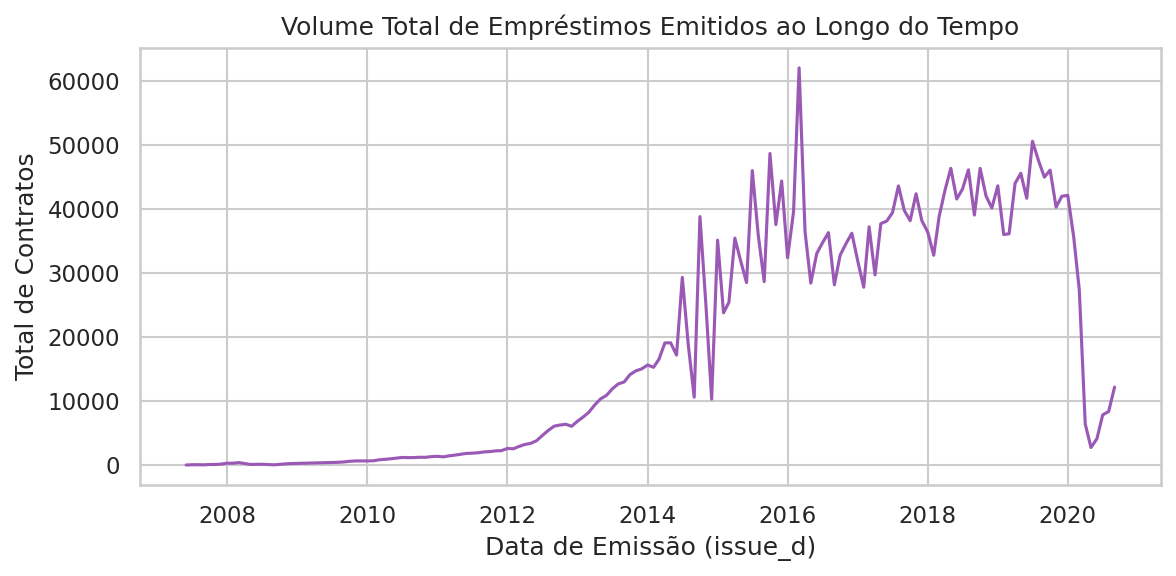

,issue_d,id
155,2020-05-01,2755
156,2020-06-01,4134
157,2020-07-01,7849
158,2020-08-01,8372
159,2020-09-01,12178


In [10]:
df_loans_over_time = df_raw.groupby("issue_d", observed=True)["id"].count().reset_index()

fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=df_loans_over_time, x="issue_d", y="id", ax=ax)
ax.set_xlabel("Data de Emissão (issue_d)")
ax.set_ylabel("Total de Contratos")
ax.set_title("Volume Total de Empréstimos Emitidos ao Longo do Tempo")
plt.tight_layout()
plt.show()

df_loans_over_time.tail()

aumento no volume de contratos a partir de 2012 reflete a expansão da operação nos Estados Unidos, seguido por oscilações cíclicas que reforçam a necessidade de validar o modelo em safras temporais distintas

### evolucao da taxa de inadimplencia (default ratio)

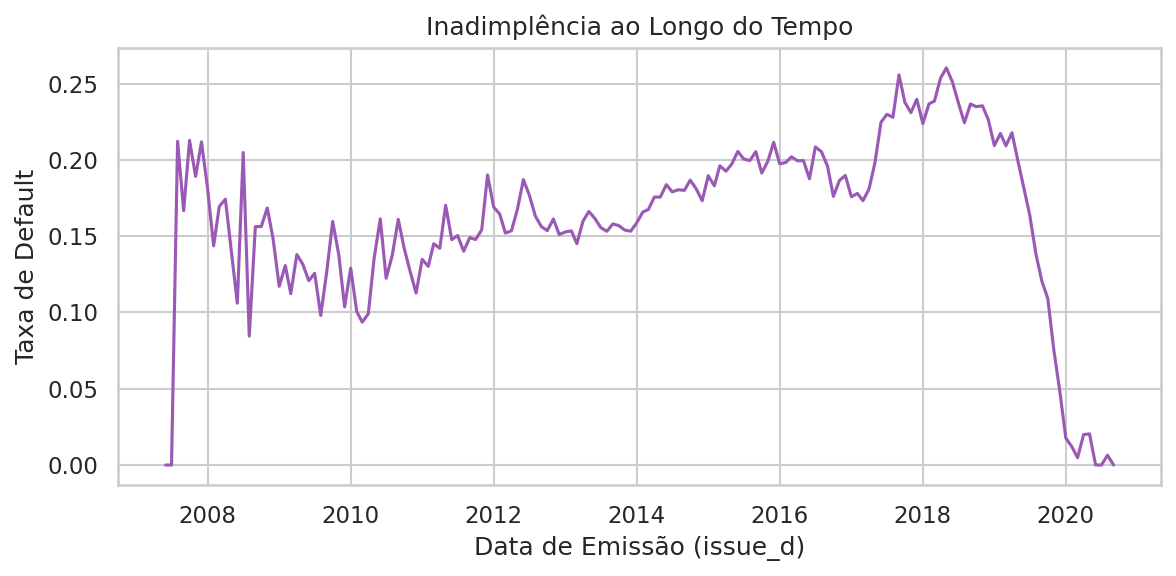

,issue_d,default
155,2020-05-01,0.020408
156,2020-06-01,0.0
157,2020-07-01,0.0
158,2020-08-01,0.006452
159,2020-09-01,0.0


In [11]:
df_default_over_time = df_raw.groupby("issue_d", observed=True)["default"].mean().reset_index()

fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=df_default_over_time, x="issue_d", y="default", ax=ax)
ax.set_xlabel("Data de Emissão (issue_d)")
ax.set_ylabel("Taxa de Default")
ax.set_title("Inadimplência ao Longo do Tempo")
plt.tight_layout()
plt.show()

df_default_over_time.dropna().tail()

### comparativo temporal --> treino (2007–2017) vs teste (2018)

comparando lado a lado a curva histórica de inadimplência do período de desenvolvimento (`2007–2017`) e a janela de avaliação (`2018`) procurando mudanças de regime na carteira

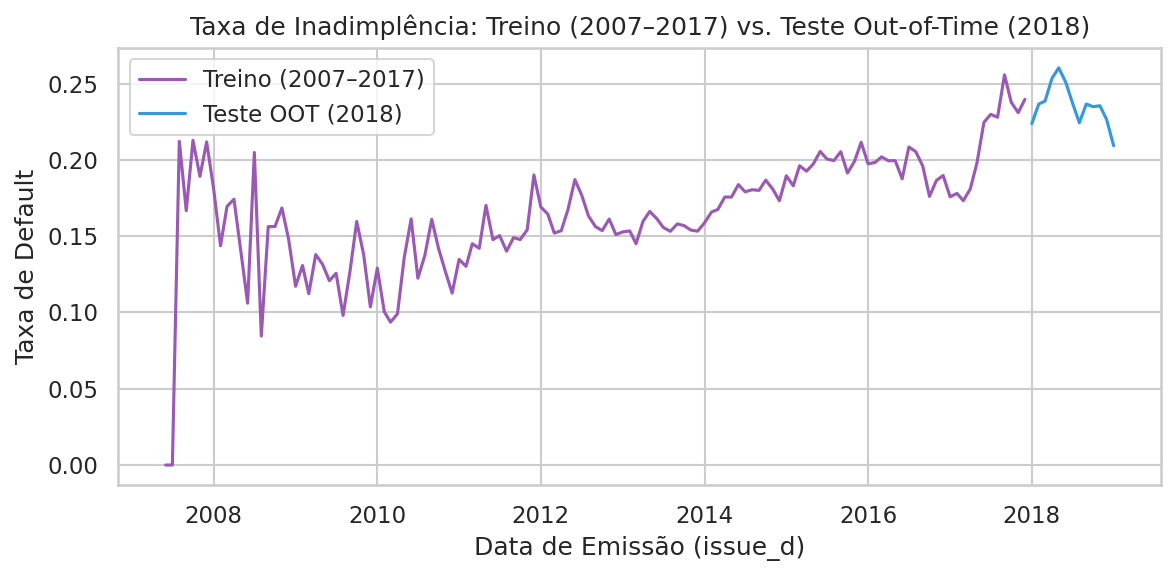

In [12]:
df_gp_train = df_train.groupby("issue_d", observed=True)["default"].mean().reset_index()
df_gp_test = df_test.groupby("issue_d", observed=True)["default"].mean().reset_index()

fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=df_gp_train, x="issue_d", y="default", label="Treino (2007–2017)", ax=ax)
sns.lineplot(data=df_gp_test, x="issue_d", y="default", label="Teste OOT (2018)", ax=ax)
ax.set_xlabel("Data de Emissão (issue_d)")
ax.set_ylabel("Taxa de Default")
ax.set_title("Taxa de Inadimplência: Treino (2007–2017) vs. Teste Out-of-Time (2018)")
ax.legend()
plt.tight_layout()
plt.show()

## Modify
---

1. **Exclusão de Variáveis Pós-Concessão (*Anti-Leakage*):** Remoção de todas as colunas alimentadas após a emissão do contrato (ex.: histórico de pagamentos realizados `total_pymnt`, recuperações `recoveries`, saldo devedor `out_prncp` e atualizações futuras de bureau `last_fico_range_high`). Essas variáveis contábeis permanecem reservadas apenas para a aferição financeira de $\text{EAD}$ e $\text{LGD}$ na etapa **Assess**.
2. **Engenharia de Atributos (*Feature Engineering*):** Criação de razões financeiras e indicadores de comprometimento de renda no momento da solicitação.
3. **Seleção de Variáveis (*Feature Selection*):** Filtragem para um conjunto enxuto, estável e auditável de preditores.

## Model
---

1. **Estratégia de Validação Interna:** Utilização exclusiva da janela `2007–2017` para treino, validação (*tuning* de hiperparâmetros) e calibração *out-of-sample*.
2. **Métrica de Otimização (Log Loss):** Como as probabilidades preditas alimentam diretamente a equação financeira de perda esperada, o modelo é treinado e calibrado visando minimizar o **Log Loss** e o **Brier Score**.

## Assess
---

### benchmarks de referencia

### formulacao da base de calibração ($\text{EAD}$, $\text{LGD}$ e $\text{Losses}$)

| indicador | lógica |
| --- | :--- |
| **Montante Total Devido ($\text{Principal}$):** | $$\text{Principal} = \text{loan\_amnt} \times (1 + \text{int\_rate})$$ |
| **Exposição no Default ($\text{EAD}$ e $\text{EAD Ratio}$):** | $$\text{EAD} = \text{Principal} - \text{total\_pymnt}, \qquad \text{EAD Ratio} = \frac{\text{EAD}}{\text{Principal}}$$ |
| **Severidade da Perda Dado o Default ($\text{LGD Ratio}$):** | $$\text{LGD Ratio} = 1 - \frac{\text{recoveries}}{\text{EAD}}$$ |
| **Perda Financeira Realizada ($\text{Losses}$):** | $$\text{Losses} = \text{Principal} - \text{total\_pymnt} + \text{recoveries}$$ |

In [13]:
def compute_credit_loss_components(df):
    result = df.copy()
    result["principal"] = result["loan_amnt"] * (1 + result["int_rate"])
    result["ead"] = result["principal"] - result["total_pymnt"]
    result["ead_ratio"] = result["ead"] / result["principal"]
    result["lgd_ratio"] = 1 - (result["recoveries"] / result["ead"])
    result["losses"] = result["principal"] - result["total_pymnt"] + result["recoveries"]
    return result


def evaluate_predictions_log_loss(test_df_with_target, predictions_df):
    merged = test_df_with_target[["id", "default"]].merge(
        predictions_df[["id", "probabilities"]], on="id"
    ).dropna()
    return pd.DataFrame(
        {
            "evaluated_loans": [len(merged)],
            "log_loss": [log_loss(merged["default"], merged["probabilities"])],
        }
    )